# Sensitivity Analysis of the Counterfactual

Tests how the counterfactual effect depends on the zone-expansion offset **δ** (0–90 min): for each δ the SLH episodes are replaced, metrics are recomputed, and the change Δ = counterfactual − observed is summarised across the cohort.

The results are produced by `python3 -m scripts.counterfactual.sensitivity_analysis --patient_id ALL` (`make sensitivity_analysis`); this notebook reads them and does not recompute anything.

Related figure scripts: `scripts/counterfactual/visualize_boxplots_sensitivity.py`, `visualize_sensitivity_lines.py`, `visualize_cdf_sensitivity.py`, `visualize_agp_sensitivity.py`.

**Usage** — from the repository root, point the notebook at a data folder and open it
(the open BrisT1D example data converted to glucose-only files is enough: `make brist1d_run`):

```bash
CGM_DATA_ROOT=$PWD/example_data/BrisT1D/converted jupyter lab notebooks/
```

**Authors:** Guillaume Deside, Laura Symul, Philippe Lysy, Zain Syed

> **Illustration only.** This notebook is run on the open **BrisT1D-Open** example data (Gordon James et al. 2025, CC BY 4.0), converted by `make brist1d` to glucose-only files (mg/dL, 5-min grid; see the README). These are not the study data: the numbers and figures illustrate what the code does and are not expected to match the manuscript, nor are they findings about BrisT1D.

## Design

| Parameter | Values |
|---|---|
| Zone-expansion offset δ | 0, 15, 30, 45, 60, 75, 90 min |
| Smoothing kernel | 60 min (fixed) |
| Signals | full 24 h and daytime only (06:00–22:00) |
| Metrics | mean, median, SD, CV, TIR 70–180, TAR >180, TAR >250, TBR <70 |

Time-in-range metrics are in percentage points; glucose metrics in mg/dL.

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether Jupyter was started from the repo root or from notebooks/
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import PATIENT_ID_COL, TIME_COL, COHORT_SENSITIVITY_CSV, SENSITIVITY_LININTERP_DATA
from src.counterfactual.counterfactual_config import OFFSET_VALUES, KERNEL_MIN, SELECTED_OFFSET_MIN
from src.counterfactual.load_counterfactual import load_patient_signals, extract_delta_values

%matplotlib inline

cohort = pd.read_csv(COHORT_SENSITIVITY_CSV)
summary = pd.read_csv(Path(SENSITIVITY_LININTERP_DATA) / "sensitivity_summary.csv")

print(f"{cohort[PATIENT_ID_COL].nunique()} patients × {cohort['offset'].nunique()} offsets")
cohort.head(3)

14 patients × 7 offsets


,patient_id,offset,kernel,orig_mean,ctf_mean,delta_mean,orig_median,ctf_median,delta_median,orig_sd,...,daytime_ctf_TAR>250,daytime_delta_TAR>250,daytime_orig_TBR<70,daytime_ctf_TBR<70,daytime_delta_TBR<70,max_median_diff_abs,max_median_diff_signed,max_median_diff_time,max_median_diff_time_hour,max_median_diff_direction
0,P02,0,60,167.48,167.10,-0.38,158.6,158.6,0.0,51.14,...,6.8801,-0.0815,0.3143,0.3143,0.0,16.2,16.2,13:45,13.750,Counterfactual < Original
1,P02,15,60,167.48,166.41,-1.07,158.6,156.8,-1.8,51.14,...,6.8801,-0.0815,0.3143,0.3143,0.0,21.6,21.6,14:20,14.333,Counterfactual < Original
2,P02,30,60,167.48,165.71,-1.77,158.6,155.0,-3.6,51.14,...,6.8801,-0.0815,0.3143,0.3143,0.0,21.6,21.6,14:20,14.333,Counterfactual < Original


## 2. Cohort summary per δ

`sensitivity_summary.csv` gives, for each metric and δ, the mean change with its 95% confidence interval, the median and the quartiles.

In [2]:
view = summary[(summary["time_window"] == "all_day") & (summary["metric"].isin(["mean", "TIR70-180", "TAR>180", "sd"]))]

view.pivot(index="offset_min", columns="metric", values="mean").round(2)

metric,TAR>180,TIR70-180,mean,sd
offset_min,,,,
0,-0.90,0.90,-0.26,-0.21
15,-1.37,1.37,-0.76,-0.30
30,-1.37,1.37,-1.27,-0.17
45,-1.37,1.33,-1.70,0.02
60,-1.37,1.28,-2.06,0.21
75,-1.37,1.23,-2.36,0.39
90,-1.37,1.16,-2.63,0.58


## 3. Change in each metric versus δ

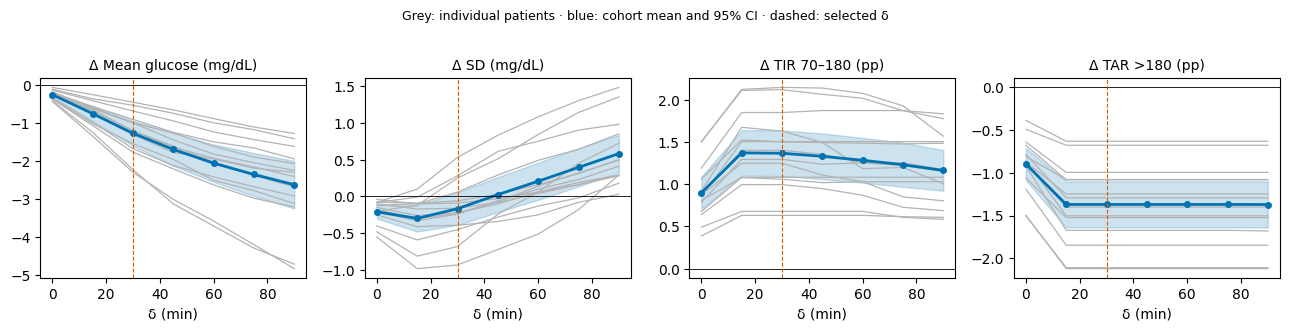

In [3]:
METRICS = [("mean", "Mean glucose (mg/dL)"), ("sd", "SD (mg/dL)"),
           ("TIR70-180", "TIR 70–180 (pp)"), ("TAR>180", "TAR >180 (pp)")]

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, (metric, label) in zip(axes, METRICS):
    for pid, grp in cohort.groupby(PATIENT_ID_COL):
        ax.plot(grp["offset"], grp[f"delta_{metric}"], color="0.7", lw=0.9)

    s = summary[(summary["time_window"] == "all_day") & (summary["metric"] == metric)]
    ax.fill_between(s["offset_min"], s["ci95_low"], s["ci95_high"], color="#0072B2", alpha=0.2)
    ax.plot(s["offset_min"], s["mean"], color="#0072B2", lw=2, marker="o", ms=4)
    ax.axhline(0, color="k", lw=0.6)
    ax.axvline(SELECTED_OFFSET_MIN, color="#D55E00", ls="--", lw=0.8)
    ax.set_xlabel("δ (min)"); ax.set_title(f"Δ {label}", fontsize=10)

fig.suptitle("Grey: individual patients · blue: cohort mean and 95% CI · dashed: selected δ", fontsize=9, y=1.02)
fig.tight_layout()
plt.show()

## 4. Distribution across patients

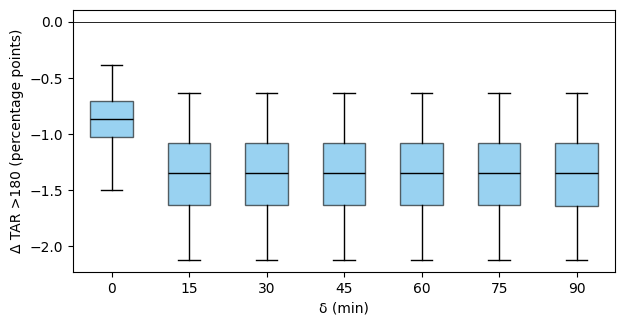

In [4]:
metric, label = "TAR>180", "Δ TAR >180 (percentage points)"
offsets = sorted(cohort["offset"].unique())

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.boxplot([cohort.loc[cohort["offset"] == o, f"delta_{metric}"] for o in offsets],
           positions=range(len(offsets)), widths=0.55, patch_artist=True,
           boxprops=dict(facecolor="#56B4E9", alpha=0.6), medianprops=dict(color="k"))
ax.set_xticks(range(len(offsets))); ax.set_xticklabels([f"{o:g}" for o in offsets])
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("δ (min)"); ax.set_ylabel(label)
plt.show()

## 5. Whole day versus daytime

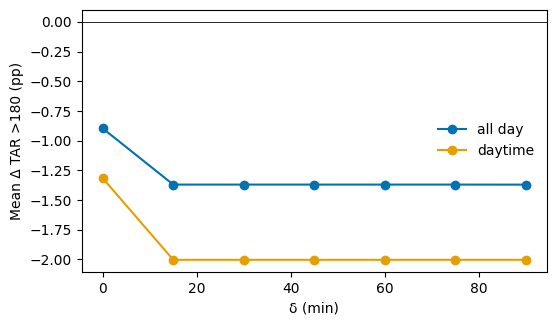

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.4))
for window, color in [("all_day", "#0072B2"), ("daytime", "#E69F00")]:
    s = summary[(summary["time_window"] == window) & (summary["metric"] == "TAR>180")]
    ax.plot(s["offset_min"], s["mean"], marker="o", color=color, label=window.replace("_", " "))
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("δ (min)"); ax.set_ylabel("Mean Δ TAR >180 (pp)"); ax.legend(frameon=False)
plt.show()

## 6. What δ does to the signal

The saved signals contain the observed glucose and one counterfactual per δ. A larger δ widens the replaced zone.

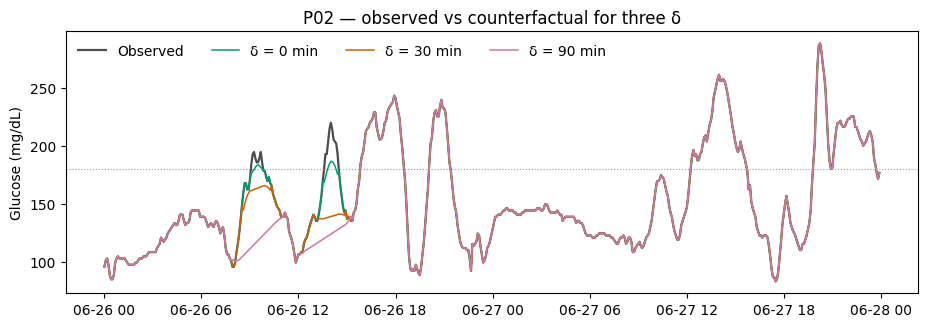

In [6]:
patient_id = cohort[PATIENT_ID_COL].iloc[0]
signals = load_patient_signals(patient_id)
deltas = extract_delta_values(signals)

day0 = signals[TIME_COL].min().normalize() + pd.Timedelta(days=2)
view = signals[(signals[TIME_COL] >= day0) & (signals[TIME_COL] < day0 + pd.Timedelta(days=2))]

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(view[TIME_COL], view["glucose_original"], color="0.3", lw=1.6, label="Observed")
for d, color in zip([deltas[0], SELECTED_OFFSET_MIN, deltas[-1]], ["#009E73", "#D55E00", "#CC79A7"]):
    ax.plot(view[TIME_COL], view[f"glucose_ctf_delta_{d}"], lw=1.1, color=color, label=f"δ = {d} min")
ax.axhline(180, color="0.6", ls=":", lw=0.8)
ax.set_ylabel("Glucose (mg/dL)"); ax.set_title(f"{patient_id} — observed vs counterfactual for three δ")
ax.legend(frameon=False, ncol=4)
plt.show()